In [1]:
import os, sys
PROJECT_ROOT = "/home/leejs/NAMS"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)
import os
import torch
from model_4c import NAMS_network
import argparse
import yaml
from datasets_loader import WaveLoader
from torch.utils.data import DataLoader
from renderer_4c import NAMS_renderer
from utils.criterion_4c import Criterion

In [2]:
logdir = "/home/leejs/NAMS/logs/pyr_multichannel_500_amang/ckpts"
# argument 불러오기
parser = argparse.ArgumentParser()
parser.add_argument('--config', type=str, default='config.yml', help='config file path')
args   = parser.parse_args(['--config', os.path.join(PROJECT_ROOT, "config_files", "pyc4.yml")])
with open(args.config, 'r') as file:
    kwargs = yaml.load(file, Loader=yaml.FullLoader)

kwargs_path    = kwargs['path']
kwargs_render  = kwargs['render']
kwargs_network = kwargs['model']
kwargs_train   = kwargs['train']
dataset_type   = kwargs_path['dataset_type']
batch_size     = 1
current_epoch  = 0
device         = torch.device("cuda:3")
ir_length      = kwargs['render']['ir_length']
fs             = kwargs['render']['fs']
dataset_dir    = kwargs['path']['dataset_dir']

train_set    = WaveLoader(base_folder = dataset_dir, dataset_type = dataset_type, eval = False, seq_len = int(ir_length*fs), fs = fs)
test_set     = WaveLoader(base_folder = dataset_dir, dataset_type = dataset_type, eval = True,  seq_len = int(ir_length*fs), fs = fs)
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader  = DataLoader(test_set,  batch_size=batch_size, shuffle=False, num_workers=4)

spk_pos      = train_set.positions_tx[0]
nams_network = NAMS_network(kwargs_network, kwargs_render)
renderer     = NAMS_renderer(networks_fn=nams_network, spk_pos=spk_pos, **kwargs_render)
criterion    = Criterion(kwargs_train)

def load_checkpoints():
    global renderer
    ckptsdir = os.path.join(logdir, "best.tar")
    ckpt     = torch.load(ckptsdir, map_location = device)
    multipoles_count = ckpt['renderer_state_dict']['position_mps'].size(0)
    print(multipoles_count)
    renderer.multipoles_count_reset(multipoles_count)
    renderer.load_state_dict(ckpt['renderer_state_dict'])
    renderer = renderer.to(device)

load_checkpoints()


/home/leejs/anaconda3/envs/nams/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


spherical multipoles.shape: (1089, 3)
712


In [3]:
# z축 고정 후 격자점에서 441개에서 딴 각각의 W채널들을 fft하고, 특정 주파수 bin만 비교
import numpy as np
import pandas as pd
import librosa
import re

def _room_prefix(roomnum):
    return f"R{roomnum:02d}"

def compute_bounds(omega_center, omega_size):
    half = omega_size / 2.0
    lb = torch.tensor([1.0 * (omega_center[0] - half), 1.0 * (omega_center[1] - half),
                       1.0 * (omega_center[2] - half)], dtype=torch.float32)
    ub = torch.tensor([1.0 * (omega_center[0] + half), 1.0 * (omega_center[1] + half),
                       1.0 * (omega_center[2] + half)], dtype=torch.float32)
    return lb.numpy(), ub.numpy()

def load_pyroomacoustics(base_folder, seq_len, fs=8000, z_index = 0):
    t_max = 0.1
    seed  = 2026
    status_ok = "Success"
    csv_path = os.path.join(base_folder, "Generated_HOA_SRIR_data.csv")
    data_dir = base_folder
    metadata = pd.read_csv(csv_path)
    prefix = _room_prefix(0) # 방 번호가 0번이라서 0 넣음
    room_mask = metadata['Name'].astype(str).str.match(rf'^{re.escape(prefix)}[_\-]?')
    if status_ok is not None and 'status' in metadata.columns:
        room_mask &= (metadata['status'] == status_ok)
    room_meta = metadata[room_mask].reset_index(drop=True)
    if len(room_meta) == 0:
        raise ValueError(f"no rows found for room '{prefix}' (status='{status_ok}') in {csv_path}")
    x   = room_meta['x_mic'].to_numpy(dtype=np.float32)
    y   = room_meta['y_mic'].to_numpy(dtype=np.float32)
    z   = room_meta['z_mic'].to_numpy(dtype=np.float32)
    xs  = room_meta['x_source'].to_numpy(dtype=np.float32)
    ys  = room_meta['y_source'].to_numpy(dtype=np.float32)
    zs  = room_meta['z_source'].to_numpy(dtype=np.float32)
    foa_list = []
    fs = None
    n_samples = None
    SN3D_MISSING_GAIN = np.sqrt(3.0)
    RAW_TO_WXYZ       = [0, 3, 1, 2]
    for name in room_meta['Name']:
        wav_path = os.path.join(data_dir, name)
        audio, file_fs = librosa.load(wav_path, sr=None, mono=False)
        if audio.ndim != 2 or audio.shape[0] != 4:
            raise ValueError(f"{wav_path}: expected 4-channel FOA audio, got shape {audio.shape}")
        if fs is None:
            fs = file_fs
            n_samples = min(int(round(t_max * fs)), audio.shape[1])
        elif file_fs != fs:
            raise ValueError(f"sample rate mismatch in {wav_path}: {file_fs} != {fs}")
        audio = audio.copy()
        audio[1:4, :] /= SN3D_MISSING_GAIN
        audio = audio[RAW_TO_WXYZ, :]
        foa_list.append(audio[:, :n_samples].T)  # (n_samples, 4)
    foa = np.stack(foa_list, axis=0).astype(np.float32)
    # 데이터는 다 받았으니, 이제 z축 고정하고 xy를 받자
    x_slice = x[z_index::21]
    y_slice = y[z_index::21]  
    z_slice = z[z_index::21]
    foa_out = foa[z_index::21, :, :] # (441, 800)
    foa_out = np.fft.rfft(foa_out, axis = 1)
    return x_slice, y_slice, z_slice, foa_out



In [ ]:
# fft
room = load_pyroomacoustics(base_folder = kwargs['path']['dataset_dir'], seq_len = 0.1, fs = 8000, z_index = 5)   
import matplotlib.pyplot as plt
freq_bin = 200
freq_hz  = 10 * freq_bin if freq_bin != 0 else 'DC'
batch_size = 16
channel = 3
H_list = []
# Step 1. 441개 receiver 위치 준비
pos_rcv_np = np.stack([room[0], room[1], room[2]], axis = -1).astype(np.float32)
pos_rcv    = torch.from_numpy(pos_rcv_np).to(device)
# Step 2. source 위치를 441번 반복
pos_ibe    = spk_pos.to(device).unsqueeze(0).expand(pos_rcv.size(0), -1) # (441, 3)

# Step 3. inference
renderer.eval()
with torch.no_grad():
    for i in range(0, pos_rcv.size(0), batch_size):
        H_batch = renderer(pos_rcv[i:i+batch_size], pos_ibe[i:i+batch_size])
        H_list.append(H_batch.cpu())
        torch.cuda.empty_cache()
H = torch.cat(H_list, dim=0)
H_complex = H[..., 0] + 1j * H[..., 1]
print(H_complex.shape)
# Step 4. 같은 freq_bin 추출 후 reshape
H_pred_2d = H_complex[:, freq_bin, :].reshape(21, 21, H_complex.shape[-1]).cpu().numpy()
mag_db_pred_2d = 20 * np.log10(np.abs(H_pred_2d[:, :, channel]) + 1e-12)
print(mag_db_pred_2d.shape)
val_2d = room[3][:, freq_bin, channel].reshape(21, 21)
print(val_2d.shape)
mag_db_2d = 20 * np.log10(np.abs(val_2d) + 1e-12) 

# Step 5. 그리기
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
im0 = axes[0].imshow(mag_db_2d.T, origin='lower',
                     extent=[room[0].min(), room[0].max(), room[1].min(), room[1].max()],
                     aspect='equal', cmap='jet', vmin=mag_db_2d.min(), vmax=mag_db_2d.max())
axes[0].set_title(f'Ground Truth ({freq_hz}Hz)')
axes[0].set_xlabel('x (m)')
axes[0].set_ylabel('y (m)')
fig.colorbar(im0, ax=axes[0], label='Magnitude (dB)')
im1 = axes[1].imshow(mag_db_pred_2d.T, origin='lower',
                     extent=[room[0].min(), room[0].max(), room[1].min(), room[1].max()],
                     aspect='equal', cmap='jet', vmin=mag_db_2d.min(), vmax=mag_db_2d.max())
axes[1].set_title(f'Predicted ({freq_hz}Hz)')
axes[1].set_xlabel('x (m)')
axes[1].set_ylabel('y (m)')
fig.colorbar(im1, ax=axes[1], label='Magnitude (dB)')

plt.tight_layout()
plt.show()


torch.Size([1, 401, 4])


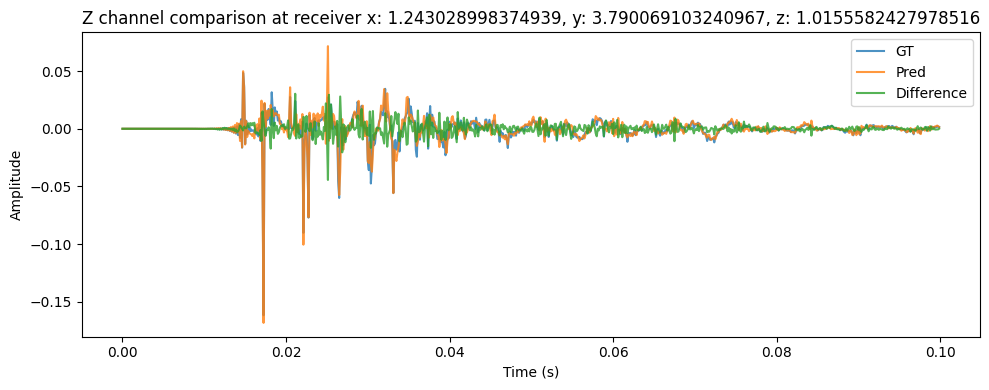

In [15]:
# 특정 위치의 RIR 비교하기
import matplotlib.pyplot as plt
channel_name = ['W', 'X', 'Y', 'Z']
channel = 3
recv_idx = 20
room = load_pyroomacoustics(base_folder = kwargs['path']['dataset_dir'], seq_len = 0.1, fs = 8000, z_index = 7)   
x = room[0][recv_idx]
y = room[1][recv_idx]
z = room[2][recv_idx]
location = f'x: {x}, y: {y}, z: {z}'
# Step 1. receiver 위치 준비
pos_rcv = torch.tensor([[x, y, z]], dtype=torch.float32).to(device)  # (1, 3)
# Step 2. source 위치를 1번 반복
pos_ibe    = spk_pos.to(device).unsqueeze(0).expand(pos_rcv.size(0), -1) # (1, 3)

# Step 3. inference
renderer.eval()
with torch.no_grad():
    H = renderer(pos_rcv, pos_ibe)
    H_complex = H[..., 0] + 1j * H[..., 1]
print(H_complex.shape)
# Step 4. 같은 freq_bin 추출 후 reshape
rir_pred = np.fft.irfft(H_complex[0,:,channel].cpu().numpy())
rir_val  = np.fft.irfft(room[3][recv_idx, :,channel])

# Step 5. 그리기
t_axis = np.arange(len(rir_pred)) / fs
plt.figure(figsize=(10, 4))
plt.plot(t_axis, rir_val, label='GT', alpha=0.8)
plt.plot(t_axis, rir_pred, label='Pred', alpha=0.8)
plt.plot(t_axis, rir_val-rir_pred, label='Difference', alpha=0.8)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title(f'{channel_name[channel]} channel comparison at receiver {location}')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 441개가 모두 같은 z평면 위에 있는지 확인하는 코드
import matplotlib.pyplot as plt
fig = plt.figure()
ax  = fig.add_subplot(projection='3d')
x = room[0]
y = room[1]
z = room[2]
ax.scatter(x, y, z)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
plt.show()

## NAMS NMSE / PCC 평가

`scratch.ipynb`(PI-DANF)의 평가 로직을 NAMS 렌더러용으로 이식한 셀들.
위쪽 셀 1(체크포인트 로드)까지 먼저 실행한 뒤 순서대로 돌리면 된다.

- **NMSE**: 모든 위치의 numerator/denominator를 합산한 뒤 한 번만 `10*log10` (per-position dB 평균 아님)
- **PCC**: 위치별로 계산 후 평균
- 평가 대상: `train(3000) + val(300)`에 한 번도 포함되지 않은 나머지 **5,961개** 리시버


In [3]:
# ============================================================
# [NAMS 평가 1/4] 전체 9,261개 리시버 로드 + train/val/eval 인덱스 복원
#   - scratch.ipynb(PI-DANF)의 NMSE/PCC 평가를 NAMS 파이프라인에 이식
#   - datasets_loader.WaveLoader.load_pyroomacoustics 와 완전히 동일한 전처리
#     (SN3D 보정 / ACN 재정렬 / ir_length 자름)를 사용해야 GT가 학습과 일치함
# ============================================================
import os, re
import numpy as np
import pandas as pd
import librosa
import torch

FOA_CACHE = os.path.join(PROJECT_ROOT, "logs", "room0_foa_all.npz")  # None 이면 캐시 안 씀


def load_pyroomacoustics_all(base_folder, ir_length=0.1, roomnum=0,
                             status_ok="Success", cache=FOA_CACHE):
    """방 전체(9,261개) 리시버의 FOA IR을 시간영역으로 반환.

    Returns dict:
        foa    : (D, L, 4) float32, 채널 순서 (W, X, Y, Z)
        pos_rx : (D, 3) float32
        pos_tx : (D, 3) float32
        names  : (D,) object
        fs     : int
    """
    if cache is not None and os.path.exists(cache):
        d = np.load(cache, allow_pickle=True)
        print(f"cache hit: {cache}")
        return dict(foa=d['foa'], pos_rx=d['pos_rx'], pos_tx=d['pos_tx'],
                    names=d['names'], fs=int(d['fs']))

    csv_path = os.path.join(base_folder, "Generated_HOA_SRIR_data.csv")
    metadata = pd.read_csv(csv_path)
    prefix = f"R{roomnum:02d}"
    room_mask = metadata['Name'].astype(str).str.match(rf'^{re.escape(prefix)}[_\-]?')
    if status_ok is not None and 'status' in metadata.columns:
        room_mask &= (metadata['status'] == status_ok)
    room_meta = metadata[room_mask].reset_index(drop=True)
    if len(room_meta) == 0:
        raise ValueError(f"no rows found for room '{prefix}' in {csv_path}")

    pos_rx = room_meta[['x_mic', 'y_mic', 'z_mic']].to_numpy(dtype=np.float32)
    pos_tx = room_meta[['x_source', 'y_source', 'z_source']].to_numpy(dtype=np.float32)

    SN3D_MISSING_GAIN = np.sqrt(3.0)
    RAW_TO_WXYZ = [0, 3, 1, 2]          # HARP 저장 순서 (W, Y, Z, X) -> (W, X, Y, Z)

    foa_list, fs, n_samples = [], None, None
    for k, name in enumerate(room_meta['Name']):
        audio, file_fs = librosa.load(os.path.join(base_folder, name), sr=None, mono=False)
        if audio.ndim != 2 or audio.shape[0] != 4:
            raise ValueError(f"{name}: expected 4-channel FOA, got {audio.shape}")
        if fs is None:
            fs = int(file_fs)
            n_samples = min(int(round(ir_length * fs)), audio.shape[1])
        elif file_fs != fs:
            raise ValueError(f"sample rate mismatch in {name}: {file_fs} != {fs}")
        audio = audio.copy()
        audio[1:4, :] /= SN3D_MISSING_GAIN
        audio = audio[RAW_TO_WXYZ, :]
        foa_list.append(audio[:, :n_samples].T)
        if (k + 1) % 1000 == 0:
            print(f"  loaded {k + 1}/{len(room_meta)}")

    out = dict(foa=np.stack(foa_list, 0).astype(np.float32),
               pos_rx=pos_rx, pos_tx=pos_tx,
               names=room_meta['Name'].to_numpy(), fs=fs)
    if cache is not None:
        os.makedirs(os.path.dirname(cache), exist_ok=True)
        np.savez_compressed(cache, **out)
        print(f"cached -> {cache}")
    return out


def rebuild_split(D_total, seed=2026, n_train=500, n_val=300):
    """WaveLoader.load_pyroomacoustics 의 split을 그대로 재현.
    (val = perm[:300], train = perm[300:3300], 나머지는 한 번도 안 본 점)"""
    rng = np.random.default_rng(seed)
    perm = rng.permutation(D_total)
    return perm[n_val:n_val + n_train], perm[:n_val], perm[n_val + n_train:]


room_all = load_pyroomacoustics_all(kwargs_path['dataset_dir'], ir_length=ir_length)
foa_all, pos_rx_all, pos_tx_all = room_all['foa'], room_all['pos_rx'], room_all['pos_tx']
D_total, L, _ = foa_all.shape
train_idx, val_idx, eval_idx = rebuild_split(D_total)

# split이 실제 학습에 쓰인 것과 같은지 검증 (틀리면 아래 지표는 전부 무의미)
assert np.allclose(pos_rx_all[train_idx], train_set.positions_rx.numpy(), atol=1e-5), \
    "train split mismatch — seed/n_train/n_val 가 datasets_loader 와 다릅니다"
assert np.allclose(pos_rx_all[val_idx], test_set.positions_rx.numpy(), atol=1e-5), \
    "val split mismatch"
print(f"total {D_total} | train {len(train_idx)} | val {len(val_idx)} | unseen(eval) {len(eval_idx)}")
print(f"IR length L = {L} samples @ {room_all['fs']} Hz")

cache hit: /home/leejs/NAMS/logs/room0_foa_all.npz
total 9261 | train 500 | val 300 | unseen(eval) 8461
IR length L = 800 samples @ 8000 Hz


In [4]:
# ============================================================
# [NAMS 평가 2/4] 추론 / 지표 함수
#   NMSE : 전체 위치의 numerator/denominator를 합산한 뒤 한 번만 log  (per-position dB 평균 아님)
#   PCC  : 위치별로 계산한 뒤 평균  (X/Y 부호 뒤집힘 같은 오류에 가장 민감)
# ============================================================
import numpy as np
import torch

try:
    from tqdm.auto import tqdm
except ImportError:                      # tqdm 없으면 그냥 통과
    def tqdm(x, **kw):
        return x


@torch.no_grad()
def nams_predict_rir(renderer, pos_rx, pos_tx, device, n_time, batch_size=16):
    """NAMS renderer로 (D, n_time, 4) 시간영역 FOA IR을 배치 추론.

    renderer.forward()는 [B, F, 4, 2] (real, imag)를 반환하고,
    이 F는 길이 int(ir_length*fs) 신호의 rfft이므로 irfft(n=n_time)로 되돌린다.
    """
    was_training = renderer.training
    renderer.eval()
    preds = np.zeros((len(pos_rx), n_time, 4), dtype=np.float32)

    for i in tqdm(range(0, len(pos_rx), batch_size), desc="NAMS inference"):
        pr = torch.as_tensor(pos_rx[i:i + batch_size], dtype=torch.float32, device=device)
        pt = torch.as_tensor(pos_tx[i:i + batch_size], dtype=torch.float32, device=device)
        H = renderer(pr, pt)                                   # [B, F, 4, 2]
        if i == 0:
            assert H.size(1) == n_time // 2 + 1, \
                f"freq bin 수 불일치: H.F={H.size(1)}, 기대값={n_time // 2 + 1}"
        H_complex = torch.complex(H[..., 0], H[..., 1])        # [B, F, 4]
        rir = torch.fft.irfft(H_complex, n=n_time, dim=1)      # [B, T, 4]
        preds[i:i + pr.size(0)] = rir.float().cpu().numpy()
        del H, H_complex, rir
        torch.cuda.empty_cache()

    if was_training:
        renderer.train()
    return preds


def pcc_1d(pred, true):
    pred_c = pred - pred.mean()
    true_c = true - true.mean()
    denom = np.linalg.norm(pred_c) * np.linalg.norm(true_c)
    if denom < 1e-12:
        return np.nan
    return float(np.dot(pred_c, true_c) / denom)


def evaluate_nmse_pcc(pred, true, channel_names=('W', 'X', 'Y', 'Z'), tag='', verbose=True):
    """pred/true: (D, T, 4). 채널별 NMSE(dB), PCC(위치평균) 및 위치별 PCC 배열 반환."""
    results = {}
    for c, name in enumerate(channel_names):
        p, t = pred[:, :, c], true[:, :, c]
        num = np.sum(np.abs(p - t) ** 2)
        den = np.sum(np.abs(t) ** 2)
        nmse_db = 10 * np.log10(num / den + 1e-30)
        pcc_vals = np.array([pcc_1d(p[i], t[i]) for i in range(p.shape[0])])
        results[name] = {'NMSE_dB': float(nmse_db),
                         'PCC': float(np.nanmean(pcc_vals)),
                         'PCC_per_pos': pcc_vals}

    xyz = [n for n in channel_names if n != 'W']
    results['XYZ_mean'] = {
        'NMSE_dB': float(np.mean([results[n]['NMSE_dB'] for n in xyz])),
        'PCC': float(np.mean([results[n]['PCC'] for n in xyz])),
    }

    if verbose:
        head = f"=== {tag} (D={pred.shape[0]}) ==="
        print(head)
        for name in channel_names:
            r = results[name]
            print(f"  [{name}]  NMSE = {r['NMSE_dB']:7.2f} dB   PCC = {r['PCC']:.3f}")
        r = results['XYZ_mean']
        print(f"  [XYZ 평균] NMSE = {r['NMSE_dB']:7.2f} dB   PCC = {r['PCC']:.3f}")
    return results

In [5]:
# ============================================================
# [NAMS 평가 3/4] unseen / train / val 각각에 대해 NMSE·PCC 산출
#   - seen(train)과 unseen의 격차가 크면 physics term이 실제로는 안 먹고
#     공간적으로 overfit 됐다는 신호 (PI-DANF 때 seen PCC 0.45 / unseen ~0)
#   - MAX_EVAL 로 unseen 점 수를 줄여서 빠르게 확인 가능 (None이면 5,961개 전부)
# ============================================================
MAX_EVAL = None          # 예: 2000
EVAL_BATCH = 16          # 3090 기준. OOM 나면 8 또는 4로

eval_sel = eval_idx if MAX_EVAL is None else eval_idx[:MAX_EVAL]

subsets = {
    'unseen (한 번도 안 본 리시버)': eval_sel,
    'val   (best 체크포인트 선택에 사용)': val_idx,
    'train (학습에 사용)': train_idx[:len(eval_sel)] if MAX_EVAL else train_idx,
}

all_results = {}
for tag, idx in subsets.items():
    pred = nams_predict_rir(renderer, pos_rx_all[idx], pos_tx_all[idx],
                            device=device, n_time=L, batch_size=EVAL_BATCH)
    all_results[tag] = evaluate_nmse_pcc(pred, foa_all[idx], tag=tag)
    all_results[tag]['_pred'] = pred
    all_results[tag]['_idx'] = idx
    print()

# 요약 표
print(f"{'subset':<40}{'W NMSE':>10}{'W PCC':>9}{'XYZ NMSE':>11}{'XYZ PCC':>10}")
for tag, r in all_results.items():
    print(f"{tag:<40}{r['W']['NMSE_dB']:>9.2f}dB{r['W']['PCC']:>9.3f}"
          f"{r['XYZ_mean']['NMSE_dB']:>10.2f}dB{r['XYZ_mean']['PCC']:>10.3f}")

NAMS inference: 100%|██████████| 529/529 [00:08<00:00, 63.58it/s]


=== unseen (한 번도 안 본 리시버) (D=8461) ===
  [W]  NMSE =   -6.05 dB   PCC = 0.911
  [X]  NMSE =   -7.21 dB   PCC = 0.903
  [Y]  NMSE =   -7.65 dB   PCC = 0.914
  [Z]  NMSE =   -7.36 dB   PCC = 0.906
  [XYZ 평균] NMSE =   -7.41 dB   PCC = 0.908



NAMS inference: 100%|██████████| 19/19 [00:00<00:00, 56.64it/s]


=== val   (best 체크포인트 선택에 사용) (D=300) ===
  [W]  NMSE =   -6.09 dB   PCC = 0.912
  [X]  NMSE =   -7.29 dB   PCC = 0.904
  [Y]  NMSE =   -7.64 dB   PCC = 0.914
  [Z]  NMSE =   -7.39 dB   PCC = 0.906
  [XYZ 평균] NMSE =   -7.44 dB   PCC = 0.908



NAMS inference: 100%|██████████| 32/32 [00:00<00:00, 70.13it/s]


=== train (학습에 사용) (D=500) ===
  [W]  NMSE =   -6.60 dB   PCC = 0.929
  [X]  NMSE =   -8.22 dB   PCC = 0.924
  [Y]  NMSE =   -8.50 dB   PCC = 0.931
  [Z]  NMSE =   -8.42 dB   PCC = 0.926
  [XYZ 평균] NMSE =   -8.38 dB   PCC = 0.927

subset                                      W NMSE    W PCC   XYZ NMSE   XYZ PCC
unseen (한 번도 안 본 리시버)                       -6.05dB    0.911     -7.41dB     0.908
val   (best 체크포인트 선택에 사용)                   -6.09dB    0.912     -7.44dB     0.908
train (학습에 사용)                              -6.60dB    0.929     -8.38dB     0.927


/tmp/ipykernel_879230/854146023.py:37: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_879230/854146023.py:37: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_879230/854146023.py:37: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_879230/854146023.py:37: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_879230/854146023.py:37: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_879230/854146023.py:37: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/home/leejs/anaconda3/envs/nams/lib/python3.10/site-packag

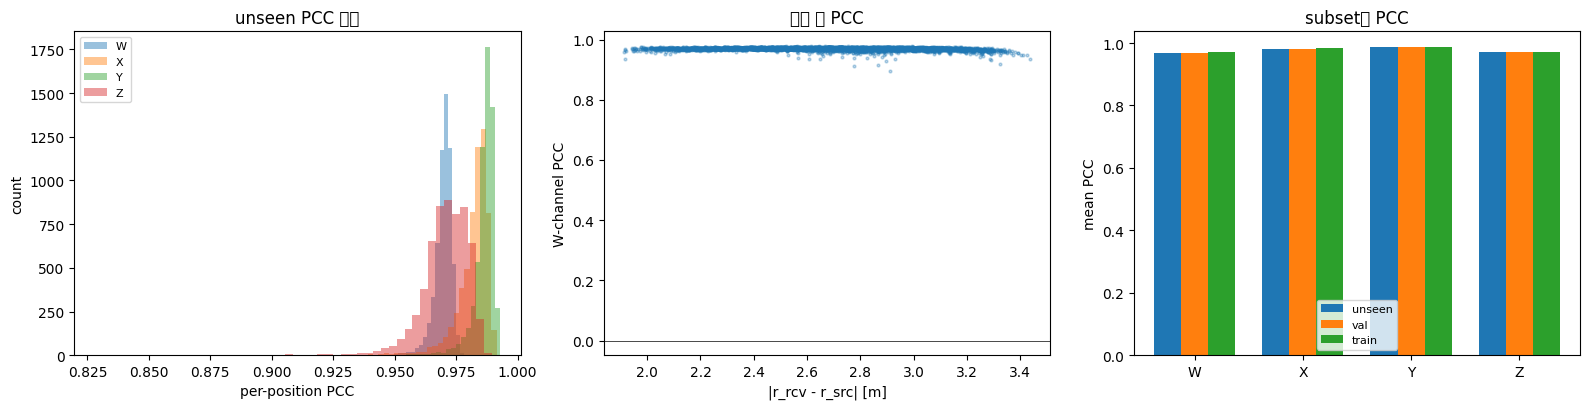

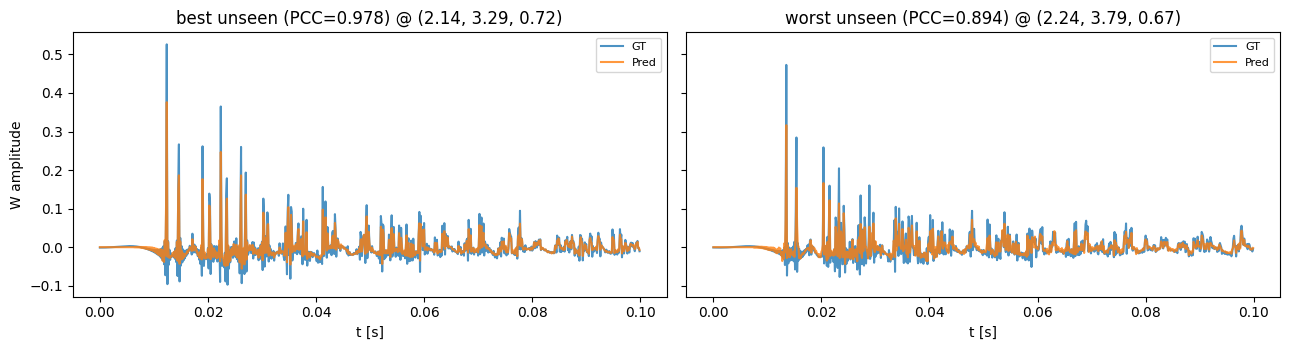

: 

In [ ]:
# ============================================================
# [NAMS 평가 4/4] 진단 플롯 — PCC 분포 / 공간 분포 / 최악·최선 사례 RIR
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

unseen_tag = 'unseen (한 번도 안 본 리시버)'
res_u = all_results[unseen_tag]
pred_u, idx_u = res_u['_pred'], res_u['_idx']
true_u = foa_all[idx_u]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (1) 채널별 위치 PCC 히스토그램
for name in ['W', 'X', 'Y', 'Z']:
    axes[0].hist(res_u[name]['PCC_per_pos'], bins=50, alpha=0.45, label=name)
axes[0].set_xlabel('per-position PCC'); axes[0].set_ylabel('count')
axes[0].set_title('unseen PCC 분포'); axes[0].legend(fontsize=8)

# (2) W채널 PCC 공간 분포 (source로부터의 거리 대비)
pcc_w = res_u['W']['PCC_per_pos']
r_src = np.linalg.norm(pos_rx_all[idx_u] - pos_tx_all[idx_u], axis=-1)
sc = axes[1].scatter(r_src, pcc_w, s=4, alpha=0.3)
axes[1].set_xlabel('|r_rcv - r_src| [m]'); axes[1].set_ylabel('W-channel PCC')
axes[1].set_title('거리 대 PCC')
axes[1].axhline(0, color='k', lw=0.5)

# (3) train / val / unseen PCC 비교 (채널별 막대)
width, chans = 0.25, ['W', 'X', 'Y', 'Z']
for k, (tag, r) in enumerate(all_results.items()):
    axes[2].bar(np.arange(4) + (k - 1) * width, [r[c]['PCC'] for c in chans],
                width=width, label=tag.split(' ')[0])
axes[2].set_xticks(np.arange(4)); axes[2].set_xticklabels(chans)
axes[2].set_ylabel('mean PCC'); axes[2].set_title('subset별 PCC')
axes[2].axhline(0, color='k', lw=0.5); axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

# 최선/최악 unseen 리시버의 W채널 파형
order = np.argsort(np.nan_to_num(pcc_w, nan=-1.0))
t_axis = np.arange(L) / room_all['fs']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, i, lab in zip(axes, [order[-1], order[0]], ['best', 'worst']):
    ax.plot(t_axis, true_u[i, :, 0], label='GT', alpha=0.8)
    ax.plot(t_axis, pred_u[i, :, 0], label='Pred', alpha=0.8)
    p = pos_rx_all[idx_u[i]]
    ax.set_title(f'{lab} unseen (PCC={pcc_w[i]:.3f}) @ '
                 f'({p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f})')
    ax.set_xlabel('t [s]'); ax.legend(fontsize=8)
axes[0].set_ylabel('W amplitude')
plt.tight_layout(); plt.show()